# Neural Operators: Learning a Whole Solver

Run it top to bottom. Every figure is produced here and saved in `images/`.

**The simulator:** a pseudo-spectral solver for the viscous Burgers equation on a periodic domain,
verified against the exact Cole–Hopf solution. A Fourier neural operator learns the map from the
initial condition to the solution at t = 0.5.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 and PyTorch are required
import sklearn
assert sklearn.__version__ >= "1.0"
import torch
torch.set_num_threads(4)

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)
torch.manual_seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## The Simulator

In [3]:
NU = 0.005                    # viscosity
T_FINAL = 0.5                 # we learn the map u(x, 0) -> u(x, 0.5)

def burgers_solve(u0, nu=NU, t_final=T_FINAL, dt=2e-4, n_snapshots=0):
    """Pseudo-spectral solver for u_t + u u_x = nu u_xx on [0, 1), periodic.
    Integrating-factor RK4: the diffusion is integrated exactly in Fourier space, the
    nonlinear term explicitly (with 2/3 dealiasing). u0 has shape (batch, N)."""
    u0 = np.atleast_2d(u0)
    N = u0.shape[1]
    k = 2 * np.pi * np.fft.rfftfreq(N, d=1 / N)                   # wavenumbers
    dealias = np.fft.rfftfreq(N, d=1 / N) < N / 3
    L = -nu * k ** 2
    E, Eh = np.exp(L * dt), np.exp(L * dt / 2)                   # decaying factors over one (half) step
    def nonlinear(u_hat):                                          # -d/dx (u^2 / 2), dealiased
        u = np.fft.irfft(u_hat, n=N)
        return -0.5j * k * np.fft.rfft(u ** 2) * dealias
    u_hat = np.fft.rfft(u0)
    n_steps = int(round(t_final / dt))
    snaps, every = [], max(1, n_steps // max(n_snapshots, 1))
    for step in range(n_steps):
        k1 = nonlinear(u_hat)
        k2 = nonlinear(Eh * (u_hat + dt / 2 * k1))
        k3 = nonlinear(Eh * u_hat + dt / 2 * k2)
        k4 = nonlinear(E * u_hat + dt * Eh * k3)
        u_hat = E * u_hat + dt / 6 * (E * k1 + 2 * Eh * (k2 + k3) + k4)
        if n_snapshots and (step + 1) % every == 0:
            snaps.append(np.fft.irfft(u_hat, n=N))
    u = np.fft.irfft(u_hat, n=N)
    return (u, np.array(snaps)) if n_snapshots else u

In [4]:
# Verification: the Cole–Hopf transformation gives an exact solution for u0 = sin(2 pi x) (via a heat equation)
def cole_hopf(x, t, nu=NU, n_quad=4096):
    """Exact solution of Burgers for u0(x) = sin(2 pi x), computed by numerical quadrature."""
    y = np.linspace(0, 1, n_quad, endpoint=False)
    phi0 = lambda s: np.exp(-(1 - np.cos(2 * np.pi * s)) / (4 * np.pi * nu))
    num, den = np.zeros_like(x), np.zeros_like(x)
    for m in range(-3, 4):                            # periodic images
        d = x[:, None] - y[None, :] - m
        g = np.exp(-d ** 2 / (4 * nu * t)) * phi0(y)[None, :]
        num += (g * d / t).sum(1); den += g.sum(1)
    return num / den

for N in (128, 256, 512, 1024):
    x = np.arange(N) / N
    u_num = burgers_solve(np.sin(2 * np.pi * x)[None], t_final=0.3)[0]
    print(f"N = {N:4d}: max error vs exact solution at t = 0.3: {np.abs(u_num - cole_hopf(x, 0.3)).max():.2e}")

N =  128: max error vs exact solution at t = 0.3: 8.05e-03


N =  256: max error vs exact solution at t = 0.3: 1.17e-04


N =  512: max error vs exact solution at t = 0.3: 1.69e-08


N = 1024: max error vs exact solution at t = 0.3: 1.29e-09


Saving figure burgers_examples_plot


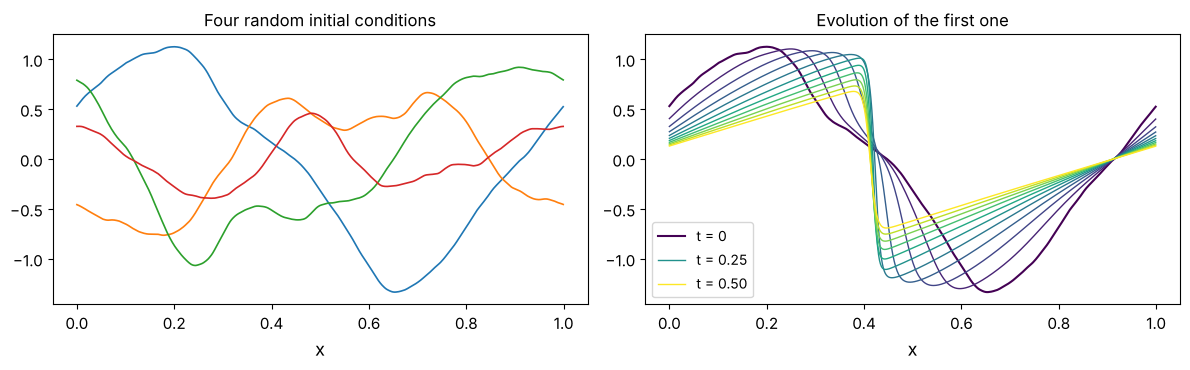

In [5]:
def random_initial_conditions(n, N=1024, alpha=2.5, tau=7.0, sigma=None, seed=0):
    """Gaussian random fields with covariance sigma^2 (-Laplacian + tau^2)^(-alpha) on the periodic domain,
    the standard benchmark distribution of the neural-operator literature."""
    rng = np.random.default_rng(seed)
    sigma = sigma if sigma is not None else 2.5 * tau ** (alpha - 0.5)
    k = np.fft.rfftfreq(N, d=1 / N)
    sqrt_eig = sigma * ((2 * np.pi * k) ** 2 + tau ** 2) ** (-alpha / 2)
    sqrt_eig[0] = 0                                    # zero mean
    coef = (rng.standard_normal((n, len(k))) + 1j * rng.standard_normal((n, len(k)))) * sqrt_eig
    return np.fft.irfft(coef, n=N) * N / np.sqrt(2)

x_fine = np.arange(1024) / 1024
u0_demo = random_initial_conditions(4, seed=1)
u1_demo, snaps = burgers_solve(u0_demo[:1], n_snapshots=10)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for u in u0_demo:
    axes[0].plot(x_fine, u, lw=1.2)
axes[0].set_title("Four random initial conditions", fontsize=12); axes[0].set_xlabel("x")
cols = plt.cm.viridis(np.linspace(0, 1, len(snaps) + 1))
axes[1].plot(x_fine, u0_demo[0], color=cols[0], lw=1.5, label="t = 0")
for i, s in enumerate(snaps):
    axes[1].plot(x_fine, s[0], color=cols[i + 1], lw=1, label=f"t = {T_FINAL * (i + 1) / len(snaps):.2f}" if i in (4, 9) else None)
axes[1].set_title("Evolution of the first one", fontsize=12); axes[1].set_xlabel("x"); axes[1].legend()
save_fig("burgers_examples_plot")
plt.show()

## Generate the Data

In [6]:
DATA_FILE = os.path.join(DATA_PATH, "burgers_nu0005.npz")
N_TRAIN, N_TEST = 1000, 200
if os.path.exists(DATA_FILE):
    d = np.load(DATA_FILE)
    U0, U1 = d["u0"], d["u1"]
    sim_time = float(d["sim_time"])
else:
    U0 = random_initial_conditions(N_TRAIN + N_TEST, seed=42)
    t0 = time.time()
    U1 = np.concatenate([burgers_solve(U0[i:i + 100]) for i in range(0, len(U0), 100)])
    sim_time = (time.time() - t0) / len(U0)
    np.savez_compressed(DATA_FILE, u0=U0.astype("f4"), u1=U1.astype("f4"), sim_time=sim_time)
print(f"{len(U0)} simulations on a 1024-point grid; {1e3 * sim_time:.0f} ms per simulation (batched)")
U0, U1 = U0.astype("f4"), U1.astype("f4")

1200 simulations on a 1024-point grid; 110 ms per simulation (batched)


In [7]:
def subsample(U, n):
    return U[:, :: U.shape[1] // n]

RES = 256                                              # training resolution
X_tr, Y_tr = subsample(U0[:N_TRAIN], RES), subsample(U1[:N_TRAIN], RES)
X_te, Y_te = subsample(U0[N_TRAIN:], RES), subsample(U1[N_TRAIN:], RES)
print(X_tr.shape, X_te.shape)

def rel_l2(pred, true):
    """Relative L2 error, averaged over samples (the standard neural-operator metric), in %."""
    return 100 * np.mean(np.linalg.norm(pred - true, axis=1) / np.linalg.norm(true, axis=1))

(1000, 256) (200, 256)


Saving figure spectrum_plot


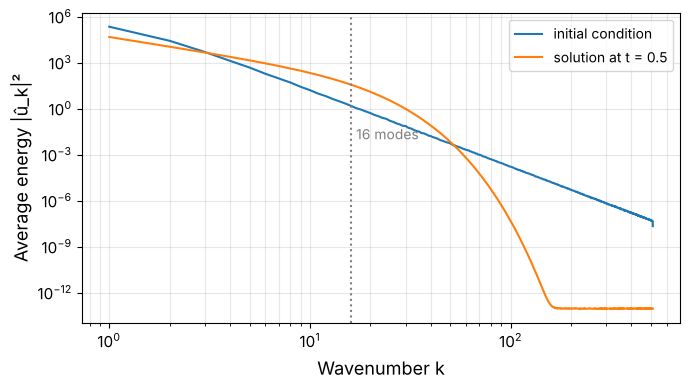

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
kk = np.fft.rfftfreq(1024, d=1 / 1024)
for U, name in ((U0, "initial condition"), (U1, "solution at t = 0.5")):
    P = np.mean(np.abs(np.fft.rfft(U, axis=1)) ** 2, axis=0)
    ax.loglog(kk[1:], P[1:], label=name)
ax.axvline(16, color="gray", ls=":")
ax.text(17, 1e-2, "16 modes", color="gray")
ax.set_xlabel("Wavenumber k"); ax.set_ylabel("Average energy |û_k|²")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
save_fig("spectrum_plot")
plt.show()

## Baselines

In [9]:
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.neural_network import MLPRegressor

results, timings = {}, {}
t0 = time.time()
ridge = Ridge(alpha=1e-3).fit(X_tr, Y_tr)
results["Linear (ridge)"] = rel_l2(ridge.predict(X_te), Y_te)

class PCAGP:
    """The classic field surrogate: PCA on inputs and outputs, a GP between the PCA scores."""
    def __init__(self, n_in=24, n_out=24):
        self.n_in, self.n_out = n_in, n_out
    def fit(self, X, Y):
        self.pin, self.pout = PCA(self.n_in).fit(X), PCA(self.n_out).fit(Y)
        Z = self.pin.transform(X)
        self.zs = Z.std(0)
        k = C(1.0) * RBF(np.ones(self.n_in), (1e-2, 1e3)) + WhiteKernel(1e-3, (1e-8, 1))
        self.gp = GaussianProcessRegressor(k, normalize_y=True, random_state=0).fit(Z / self.zs, self.pout.transform(Y))
        return self
    def predict(self, X):
        return self.pout.inverse_transform(self.gp.predict(self.pin.transform(X) / self.zs))

pcagp = PCAGP().fit(X_tr, Y_tr)
results["PCA + Gaussian process"] = rel_l2(pcagp.predict(X_te), Y_te)
mlp = MLPRegressor(hidden_layer_sizes=(512, 512), alpha=1e-4, max_iter=500, early_stopping=True, random_state=42).fit(X_tr, Y_tr)
results["MLP (vector to vector)"] = rel_l2(mlp.predict(X_te), Y_te)
print(f"({time.time() - t0:.0f} s)")
pd.Series(results, name="test relative L2 error (%)").round(2)

(1123 s)


Linear (ridge)            67.62
PCA + Gaussian process    20.50
MLP (vector to vector)    20.13
Name: test relative L2 error (%), dtype: float64

## The Fourier Neural Operator

In [10]:
import torch.nn as nn

class SpectralConv1d(nn.Module):
    """The heart of the FNO: FFT -> multiply the lowest `modes` frequencies by learned complex
    weights (mixing channels) -> inverse FFT. Higher frequencies are set to zero."""
    def __init__(self, width, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (width * width)
        self.w = nn.Parameter(scale * torch.randn(width, width, modes, dtype=torch.cfloat))
    def forward(self, v):                                   # v: (batch, width, n)
        v_hat = torch.fft.rfft(v)
        out = torch.zeros_like(v_hat)
        m = min(self.modes, v_hat.shape[-1])
        out[:, :, :m] = torch.einsum("bik,iok->bok", v_hat[:, :, :m], self.w[:, :, :m])
        return torch.fft.irfft(out, n=v.shape[-1])

class FNO1d(nn.Module):
    def __init__(self, modes=16, width=32, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)                     # input channels: u0(x) and x
        self.spectral = nn.ModuleList([SpectralConv1d(width, modes) for _ in range(n_layers)])
        self.local = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))
        self.n_layers = n_layers
    def forward(self, u0):                                  # u0: (batch, n), any n
        n = u0.shape[-1]
        x = torch.linspace(0, 1, n + 1, device=u0.device)[:-1].expand(u0.shape[0], n)
        v = self.lift(torch.stack([u0, x], dim=-1)).permute(0, 2, 1)
        for i, (sc, lc) in enumerate(zip(self.spectral, self.local)):
            v = sc(v) + lc(v)
            if i < self.n_layers - 1:
                v = nn.functional.gelu(v)
        return self.proj(v.permute(0, 2, 1)).squeeze(-1)

fno = FNO1d()
print(f"{sum(p.numel() for p in fno.parameters()):,} parameters")

74,209 parameters


In [11]:
def train_fno(model, X, Y, epochs=300, batch=20, lr=1e-3, seed=42, log=50):
    torch.manual_seed(seed)
    Xt, Yt = torch.tensor(X), torch.tensor(Y)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xt))
        tot = 0.0
        for i in range(0, len(Xt), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            pred = model(Xt[idx])
            loss = torch.mean(torch.norm(pred - Yt[idx], dim=1) / torch.norm(Yt[idx], dim=1))
            loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        sched.step()
        if ep % log == 0 or ep == epochs - 1:
            with torch.no_grad():
                te = rel_l2(model(torch.tensor(X_te)).numpy(), Y_te)
            hist.append((ep, 100 * tot / len(Xt), te))
    return pd.DataFrame(hist, columns=["epoch", "train_rel_l2", "test_rel_l2"])

t0 = time.time()
hist = train_fno(fno, X_tr, Y_tr)
fno_train_time = time.time() - t0
print(f"trained in {fno_train_time / 60:.1f} min")
hist.round(2)

trained in 3.5 min


,epoch,train_rel_l2,test_rel_l2
0,0,64.36,36.990002
1,50,1.73,1.620000
2,100,1.19,1.340000
3,150,0.69,0.860000
4,200,0.47,0.620000
5,250,0.30,0.470000
6,299,0.26,0.440000


In [12]:
fno.eval()
with torch.no_grad():
    P_fno = fno(torch.tensor(X_te)).numpy()
results["Fourier neural operator"] = rel_l2(P_fno, Y_te)
pd.Series(results, name="test relative L2 error (%)").round(2)

Linear (ridge)             67.62
PCA + Gaussian process     20.50
MLP (vector to vector)     20.13
Fourier neural operator     0.44
Name: test relative L2 error (%), dtype: float64

Saving figure test_examples_plot


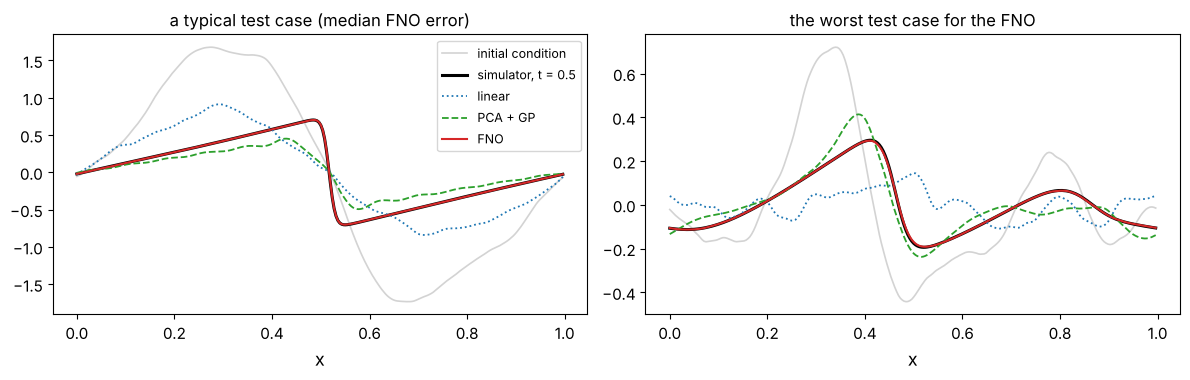

In [13]:
x256 = np.arange(RES) / RES
P_ridge, P_gp, P_mlp = ridge.predict(X_te), pcagp.predict(X_te), mlp.predict(X_te)
err = np.linalg.norm(P_fno - Y_te, axis=1) / np.linalg.norm(Y_te, axis=1)
picks = [np.argsort(err)[len(err) // 2], np.argmax(err)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, i, title in zip(axes, picks, ("a typical test case (median FNO error)", "the worst test case for the FNO")):
    ax.plot(x256, X_te[i], color="lightgray", lw=1.2, label="initial condition")
    ax.plot(x256, Y_te[i], "k", lw=2.2, label="simulator, t = 0.5")
    ax.plot(x256, P_ridge[i], "C0:", lw=1.3, label="linear")
    ax.plot(x256, P_gp[i], "C2--", lw=1.3, label="PCA + GP")
    ax.plot(x256, P_fno[i], "C3", lw=1.5, label="FNO")
    ax.set_title(title, fontsize=12); ax.set_xlabel("x")
axes[0].legend(fontsize=9)
save_fig("test_examples_plot")
plt.show()

In [14]:
rows = []
for n in (100, 250, 500, 1000):
    m_ = FNO1d()
    h_ = train_fno(m_, X_tr[:n], Y_tr[:n], epochs=max(120, 300 * 250 // n), log=1000)
    g_ = PCAGP().fit(X_tr[:n], Y_tr[:n])
    rows.append(dict(n_train=n, FNO=h_.test_rel_l2.iloc[-1], PCA_GP=rel_l2(g_.predict(X_te), Y_te),
                     linear=rel_l2(Ridge(alpha=1e-3).fit(X_tr[:n], Y_tr[:n]).predict(X_te), Y_te)))
lc = pd.DataFrame(rows).set_index("n_train")
lc.round(2)

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:264: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.7202831159579546e-08.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:264: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.780164625766247e-09.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 7.149316139098971e-10.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


,FNO,PCA_GP,linear
n_train,,,
100,5.58,100.80,99.089996
250,2.02,100.44,80.209999
500,1.23,27.69,72.370003
1000,0.58,20.50,67.620003


## Super-Resolution, Speed, and Out-of-Distribution Inputs

In [15]:
rows = []
for n in (64, 128, 256, 512, 1024):
    Xn, Yn = subsample(U0[N_TRAIN:], n), subsample(U1[N_TRAIN:], n)
    with torch.no_grad():
        Pn = fno(torch.tensor(Xn)).numpy()
    rows.append(dict(resolution=n, FNO_rel_l2=rel_l2(Pn, Yn)))
pd.DataFrame(rows).set_index("resolution").round(2)

,FNO_rel_l2
resolution,
64,0.45
128,0.44
256,0.44
512,0.44
1024,0.44


In [16]:
Xt_ = torch.tensor(subsample(U0[N_TRAIN:], 1024))
with torch.no_grad():
    fno(Xt_[:10])
    t0 = time.time(); fno(Xt_); t_fno = (time.time() - t0) / len(Xt_)
t0 = time.time(); burgers_solve(U0[N_TRAIN:N_TRAIN + 20]); t_sim = (time.time() - t0) / 20
print(f"simulator: {1e3 * t_sim:.1f} ms per case (batched), FNO: {1e3 * t_fno:.2f} ms per case: x{t_sim / t_fno:.0f}")

simulator: 132.1 ms per case (batched), FNO: 0.78 ms per case: x169


In [17]:
rows = []
for name, kw in (("training distribution", dict()), ("rougher (alpha = 2)", dict(alpha=2.0)),
                 ("smoother (alpha = 3.5)", dict(alpha=3.5)), ("twice the amplitude", dict(sigma=2 * 2.5 * 7.0 ** 2.0))):
    U0o = random_initial_conditions(100, seed=7, **kw)
    U1o = burgers_solve(U0o)
    with torch.no_grad():
        Po = fno(torch.tensor(subsample(U0o, RES).astype("f4"))).numpy()
    rows.append(dict(inputs=name, input_rms=np.sqrt(np.mean(U0o ** 2)), FNO_rel_l2=rel_l2(Po, subsample(U1o, RES))))
pd.DataFrame(rows).set_index("inputs").round(2)

,input_rms,FNO_rel_l2
inputs,,
training distribution,0.65,0.42
rougher (alpha = 2),0.78,1.50
smoother (alpha = 3.5),0.46,0.22
twice the amplitude,1.29,2.67


## Use the Surrogate: An Inverse Problem

In [18]:
# Recover the initial condition from a noisy observation of the solution at t = 0.5,
# by gradient descent THROUGH the differentiable FNO.
i = picks[0]
rng = np.random.default_rng(0)
y_obs = torch.tensor(Y_te[i] + 0.02 * rng.standard_normal(RES).astype("f4"))
for p in fno.parameters():
    p.requires_grad_(False)

def check_with_simulator(u0_256):
    """Run the real solver from a recovered initial condition (interpolated spectrally to 1024 points)."""
    c = np.fft.rfft(u0_256)
    c_fine = np.zeros(513, complex); c_fine[:len(c)] = c * 4
    return subsample(burgers_solve(np.fft.irfft(c_fine, n=1024)[None]), RES)[0]

def invert(param, n_iter=1500, lr=0.02):
    """param: a function z -> u0 (1, 256); returns the recovered u0 and the FNO's misfit."""
    z, prior = param["z0"].clone().requires_grad_(True), param["prior"]
    opt = torch.optim.Adam([z], lr=lr)
    for it in range(n_iter):
        opt.zero_grad()
        misfit = torch.mean((fno(param["u0"](z))[0] - y_obs) ** 2)
        (misfit + prior(z)).backward(); opt.step()
    return param["u0"](z).detach().numpy()[0], misfit.item()

# 1. Naive: optimize the 256 grid values directly, with a mild smoothness penalty
k_ = torch.fft.rfftfreq(RES, d=1 / RES)
naive = dict(z0=torch.zeros(1, RES), u0=lambda z: z,
             prior=lambda z: 1e-4 * torch.mean(torch.abs(torch.fft.rfft(z[0]) * k_) ** 2) / RES ** 2)
# 2. In-distribution: u0 = mean + sum_k c_k * phi_k (the 40 leading PCA modes of the training inputs),
#    with the Gaussian prior that the training distribution implies for the coefficients
pca_u0 = PCA(40).fit(X_tr)
Phi = torch.tensor(pca_u0.components_, dtype=torch.float32)
mu0 = torch.tensor(pca_u0.mean_, dtype=torch.float32)
sd = torch.tensor(np.sqrt(pca_u0.explained_variance_), dtype=torch.float32)
noise_var = 0.02 ** 2
prior_pca = dict(z0=torch.zeros(1, 40), u0=lambda z: mu0 + (z * sd) @ Phi,
                 prior=lambda z: 0.5 * noise_var / RES * torch.sum(z ** 2) * 2)
rows, recovered = [], {}
t0 = time.time()
for name, param in (("naive (grid values)", naive), ("PCA prior (in-distribution)", prior_pca)):
    u0_hat, mis = invert(param)
    u1_sim = check_with_simulator(u0_hat)
    recovered[name] = (u0_hat, u1_sim)
    rows.append({"method": name, "FNO misfit (rel. %)": 100 * np.sqrt(mis) / np.sqrt(np.mean(Y_te[i] ** 2)),
                 "simulator misfit (rel. %)": 100 * np.linalg.norm(u1_sim - Y_te[i]) / np.linalg.norm(Y_te[i]),
                 "error on u0 (rel. %)": 100 * np.linalg.norm(u0_hat - X_te[i]) / np.linalg.norm(X_te[i])})
print(f"({time.time() - t0:.0f} s)")
inv = pd.DataFrame(rows).set_index("method")
inv.round(1)

(11 s)


,FNO misfit (rel. %),simulator misfit (rel. %),error on u0 (rel. %)
method,,,
naive (grid values),4.1,25.8,56.599998
PCA prior (in-distribution),4.8,1.0,60.099998


Saving figure inverse_problem_plot


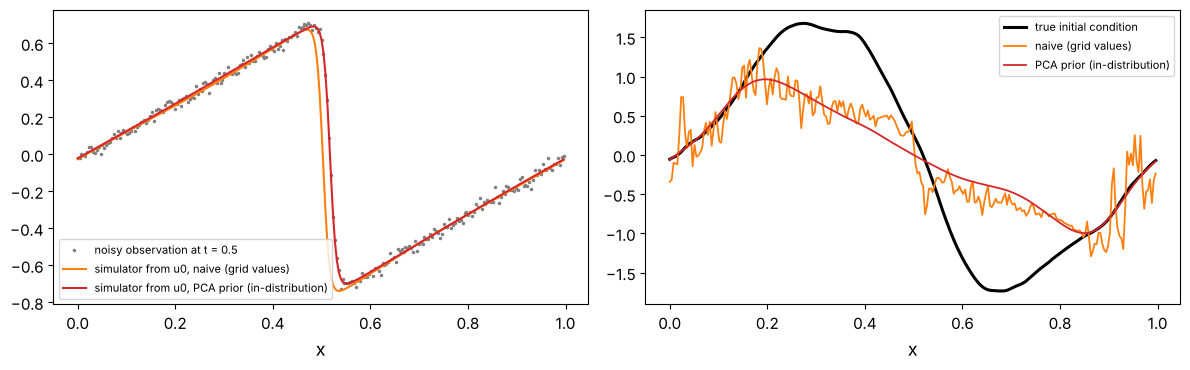

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(x256, y_obs.numpy(), ".", ms=3, color="gray", label="noisy observation at t = 0.5")
axes[1].plot(x256, X_te[i], "k", lw=2.2, label="true initial condition")
for (name, (u0_hat, u1_sim)), col in zip(recovered.items(), ("C1", "C3")):
    axes[0].plot(x256, u1_sim, col, lw=1.5, label=f"simulator from u0, {name}")
    axes[1].plot(x256, u0_hat, col, lw=1.3, label=name)
for ax in axes:
    ax.set_xlabel("x"); ax.legend(fontsize=8)
save_fig("inverse_problem_plot")
plt.show()

## Launch

In [20]:
torch.save(fno.state_dict(), "burgers_fno.pt")
print("saved", os.path.getsize("burgers_fno.pt") // 1024, "KB")

saved 552 KB


In [21]:
import json
os.makedirs("animations", exist_ok=True)
sd = {k: v.detach().numpy() for k, v in fno.state_dict().items()}
def arr(a, d=5):
    return np.round(a, d).tolist()
anim = dict(
    nu=NU, modes=16, width=32, n_layers=4,
    lift_w=arr(sd["lift.weight"]), lift_b=arr(sd["lift.bias"]),
    spec_re=[arr(sd[f"spectral.{l}.w"].real) for l in range(4)], spec_im=[arr(sd[f"spectral.{l}.w"].imag) for l in range(4)],
    loc_w=[arr(sd[f"local.{l}.weight"][:, :, 0]) for l in range(4)], loc_b=[arr(sd[f"local.{l}.bias"]) for l in range(4)],
    p1_w=arr(sd["proj.0.weight"]), p1_b=arr(sd["proj.0.bias"]), p2_w=arr(sd["proj.2.weight"]), p2_b=arr(sd["proj.2.bias"]),
    check_u0=arr(X_te[0], 6), check_y=arr(P_fno[0], 6), test_u0=arr(X_te[:12], 4), test_u1=arr(Y_te[:12], 4))
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f, separators=(",", ":"))
print("exported", os.path.getsize(os.path.join("animations", "data.json")) // 1024, "KB")

exported 2959 KB
